In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [2]:

df = pd.read_csv("/content/PhiUSIIL_Phishing_URL_Dataset.csv")

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nTarget label counts:")
print(df["label"].value_counts())


Dataset shape: (65984, 56)

First 5 rows:
     FILENAME                                 URL  URLLength  \
0  521848.txt    https://www.southbankmosaics.com         31   
1   31372.txt            https://www.uni-mainz.de         23   
2  597387.txt      https://www.voicefmradio.co.uk         29   
3  554095.txt         https://www.sfnmjournal.com         26   
4  151578.txt  https://www.rewildingargentina.org         33   

                       Domain  DomainLength  IsDomainIP  TLD  \
0    www.southbankmosaics.com          24.0         0.0  com   
1            www.uni-mainz.de          16.0         0.0   de   
2      www.voicefmradio.co.uk          22.0         0.0   uk   
3         www.sfnmjournal.com          19.0         0.0  com   
4  www.rewildingargentina.org          26.0         0.0  org   

   URLSimilarityIndex  CharContinuationRate  TLDLegitimateProb  ...  Pay  \
0               100.0              1.000000           0.522907  ...  0.0   
1               100.0              0

In [4]:

df = df.dropna(subset=["label"])

y = (df["label"] == 0).astype(int)

X = df.select_dtypes(include="number").drop(
    columns=["label"], errors="ignore"
)
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

print("Feature shape:", X.shape)
print("\nTarget counts:")
print(y.value_counts())


Feature shape: (65983, 50)

Target counts:
label
0    38445
1    27538
Name: count, dtype: int64


In [5]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])


Training records: 52786
Testing records: 13197


In [6]:

model = DecisionTreeClassifier(
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)

print("Decision Tree training completed!")


Decision Tree training completed!


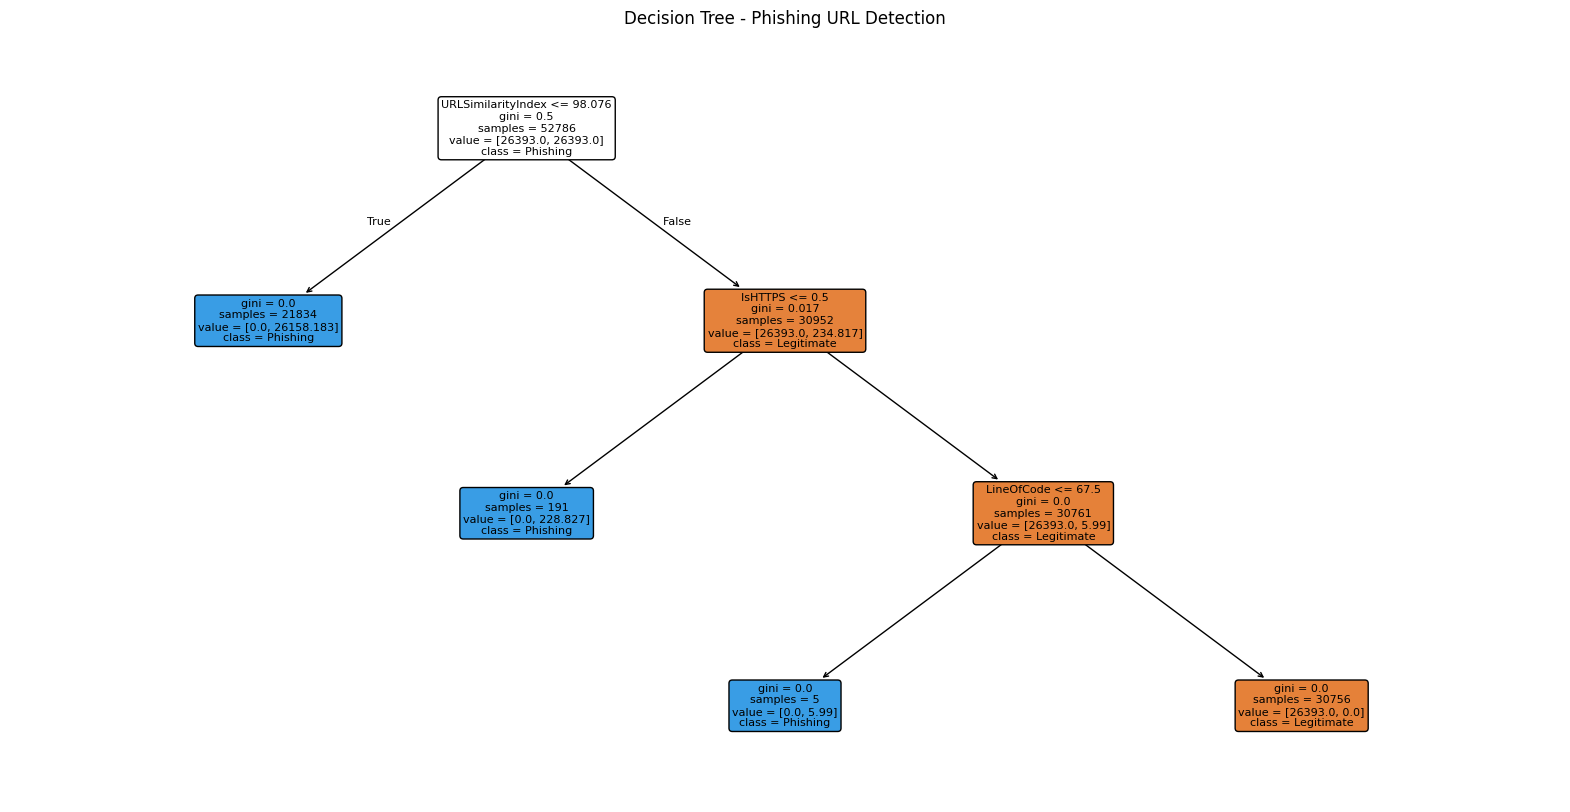

In [7]:

plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Legitimate", "Phishing"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree - Phishing URL Detection")
plt.show()


In [8]:

y_pred = model.predict(X_test)

print("Actual labels:")
print(y_test.head(10).to_numpy())

print("Predicted labels:")
print(y_pred[:10])


Actual labels:
[0 1 0 1 1 1 0 1 0 0]
Predicted labels:
[0 1 0 1 1 1 0 1 0 0]


Confusion Matrix:
[[7689    0]
 [   0 5508]]


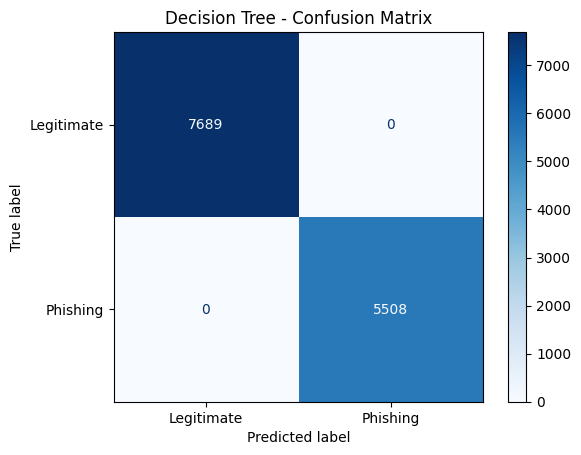

In [9]:

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Phishing"]
).plot(cmap="Blues", values_format="d")

plt.title("Decision Tree - Confusion Matrix")
plt.show()


In [12]:
from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

specificity = tn / (tn + fp) if (tn + fp) != 0 else 0

In [13]:

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)



print("MODEL EVALUATION RESULTS")
print("------------------------")
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"F1-score    : {f1:.4f}")
print(f"Specificity : {specificity:.4f}")


MODEL EVALUATION RESULTS
------------------------
Accuracy    : 1.0000
Precision   : 1.0000
Recall      : 1.0000
F1-score    : 1.0000
Specificity : 1.0000
